# Init sweep: which first-layer neuron captures u_0, and why

Analysis notebook for the two sweeps produced by `python -m layer_lenses.init_sweep`
(see that module's docstring and `results/init_sweep/run_all.sh`).

**Part A, invariance.** A few inits, each trained with 3 data samples x 2 batch sizes on the
same ODT, first-layer trajectory stored. Question: is the neuron that captures u_0 a property
of the init alone, for a fixed optimizer?

**Part B, init sweep.** ~200 inits, one run each, full parameter trajectory stored. Question:
what property of the init picks the winner?

Both use constant-LR SGD with momentum and stop when the trailing one-epoch training loss
falls below 0.3. Snapshots are indexed by optimizer step (every 100 steps), so runs with
different batch sizes are compared at equal flow time. "Capture" means |cos(w_k, u_0)| >= 0.95,
either sign. Because two neurons often cross within a few hundred steps of each other, the
analysis works with the **leading set** (everyone crossing within `TIE_WINDOW_STEPS` of the
first) as well as the single first crosser.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

from layer_lenses.init_sweep import (
    FIRST_LAYER_KEY,
    SweepRunSpec,
    build_data,
    first_layer_agreement,
    init_neuron_features,
    load_run,
    load_tree,
    part_a_invariance_table,
    signed_cosines_with_direction,
    sweep_capture_table,
    winner_prediction_cv,
    winner_rank_table,
)

PART_A_DIR = Path("../results/init_sweep/partA")
PART_B_DIR = Path("../results/init_sweep/partB")
REFERENCE_DATA_SEED = 5178
REFERENCE_BATCH_SIZE = 10_000
THRESHOLD = 0.95
TIE_WINDOW_STEPS = 500
DEVICE = "cuda"

## Part A: invariance of the u_0 capture to data sample and batch size

In [2]:
per_init, per_run = part_a_invariance_table(
    PART_A_DIR,
    reference_data_seed=REFERENCE_DATA_SEED,
    reference_batch_size=REFERENCE_BATCH_SIZE,
    threshold=THRESHOLD,
    tie_window_steps=TIE_WINDOW_STEPS,
)
print(f"{len(per_run)} runs over {len(per_init)} inits")
display(per_init)
print("inits where every run has the same first crosser:      ", int(per_init.all_same_winner.sum()), "/", len(per_init))
print("inits where every leading set equals the reference's:  ", int(per_init.all_leading_sets_equal_ref.sum()), "/", len(per_init))
print("inits where every leading set meets the reference's:   ", int(per_init.all_leading_sets_meet_ref.sum()), "/", len(per_init))

36 runs over 6 inits


,init_seed,n_runs,ref_winner,ref_winner_step,ref_leading_set,distinct_winners,all_same_winner,all_leading_sets_equal_ref,all_leading_sets_meet_ref,worst_min_row_cos_at_cross,worst_min_row_cos_end
0,6178,6,30,9800,"30,37",30,1,1,1,0.920765,-0.156484
1,6201,6,20,10100,"20,23",20,1,0,1,0.660376,-0.452393
2,6202,6,12,10100,12,12,1,0,1,0.872858,-0.117401
3,6203,6,38,11000,38,38,1,1,1,0.670522,-0.187799
4,6204,6,5,10400,5,"5,9",0,0,1,0.853180,-0.890209
5,6205,6,26,12100,26,26,1,0,1,0.726814,-0.340860


inits where every run has the same first crosser:       5 / 6
inits where every leading set equals the reference's:   2 / 6
inits where every leading set meets the reference's:    6 / 6


In [3]:
cols = ["init_seed", "data_seed", "batch_size", "final_step", "final_loss", "winner", "winner_step",
        "runner_up", "gap_steps", "leading_set", "on_direction_end",
        "min_row_cos_vs_ref_at_cross", "min_row_cos_vs_ref_end", "median_row_cos_vs_ref_end"]
display(per_run[cols].sort_values(["init_seed", "data_seed", "batch_size"]).reset_index(drop=True))

,init_seed,data_seed,batch_size,final_step,final_loss,winner,winner_step,runner_up,gap_steps,leading_set,on_direction_end,min_row_cos_vs_ref_at_cross,min_row_cos_vs_ref_end,median_row_cos_vs_ref_end
0,6178,5178,1000,47200,0.299863,30,10600,37,0,"30,37","1,30,37",0.994342,-0.156484,0.950107
1,6178,5178,10000,35200,0.299708,30,9800,37,200,"30,37","0,16,30,37",1.000000,1.000000,1.000000
2,6178,5279,1000,40400,0.299548,30,10600,37,0,"30,37","16,30,37",0.933821,-0.087860,0.868270
3,6178,5279,10000,32200,0.298045,30,9800,37,200,"30,37","16,30,37",0.920986,-0.101943,0.668519
4,6178,5380,1000,48600,0.299435,30,10600,37,200,"30,37","22,30,36,37",0.920765,-0.070958,0.379780
5,6178,5380,10000,37400,0.299756,30,9800,37,200,"30,37","14,15,22,30,37",0.922782,-0.058534,0.340350
6,6201,5178,1000,50000,0.299833,20,11500,23,1100,20,"20,23",0.982836,0.002320,0.973558
7,6201,5178,10000,38600,0.298594,20,10100,23,300,"20,23","20,23,35",1.000000,1.000000,1.000000
8,6201,5279,1000,39000,0.299919,20,11300,23,7100,20,"20,23",0.692708,-0.125899,0.921728
9,6201,5279,10000,34300,0.299891,20,10000,23,600,20,"20,23",0.675455,-0.135990,0.867573


Row-wise cosine between each run's first layer and the reference run's, at equal step count.
A value of 1 means the two runs are the same trajectory neuron for neuron; the vertical line marks
the reference winner's crossing step.

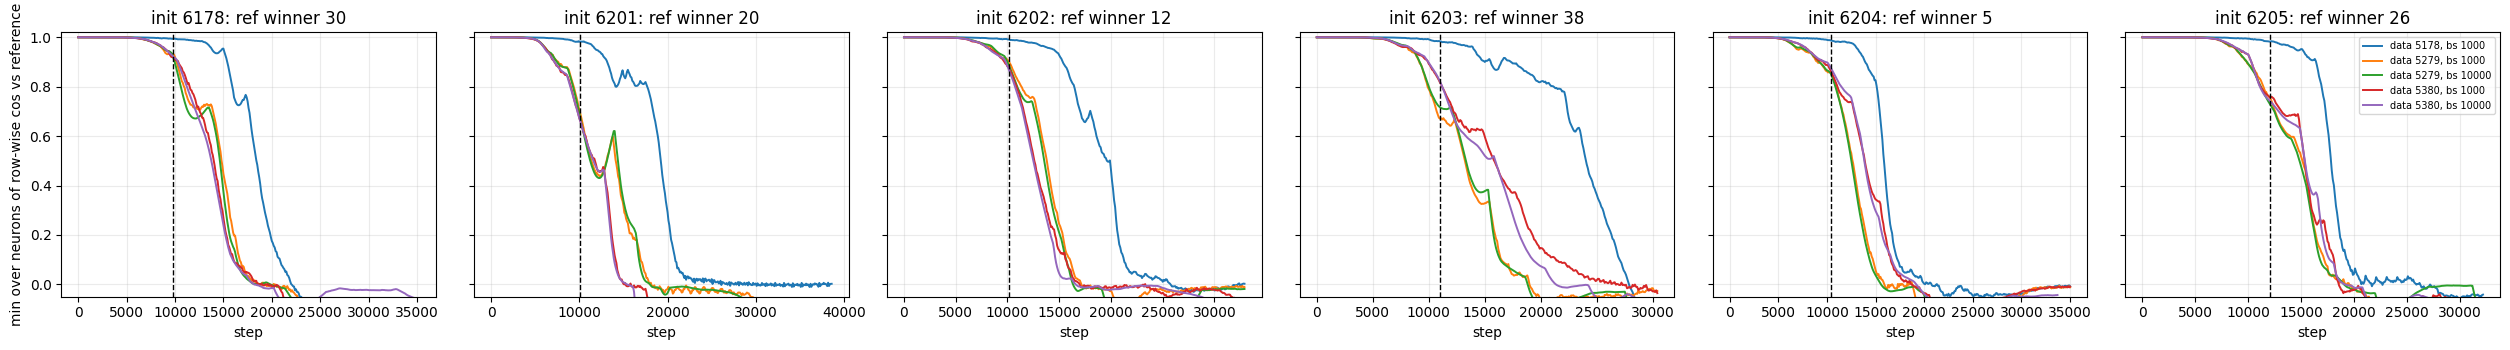

In [4]:
runs_a = {r.run_id: load_run(r.path) for r in per_run.itertuples()}
inits = sorted(per_init.init_seed)
fig, axes = plt.subplots(1, len(inits), figsize=(4.2 * len(inits), 3.6), sharey=True, squeeze=False)
for ax, init_seed in zip(axes[0], inits):
    grp = per_run[per_run.init_seed == init_seed]
    ref = grp[(grp.data_seed == REFERENCE_DATA_SEED) & (grp.batch_size == REFERENCE_BATCH_SIZE)].iloc[0]
    for r in grp.itertuples():
        if r.run_id == ref.run_id:
            continue
        ag = first_layer_agreement(runs_a[ref.run_id], runs_a[r.run_id])
        ax.plot(ag.step, ag.min_cos, label=f"data {r.data_seed}, bs {r.batch_size}", lw=1.4)
    ax.axvline(ref.winner_step, color="k", ls="--", lw=1)
    ax.set_title(f"init {init_seed}: ref winner {ref.winner}")
    ax.set_xlabel("step"); ax.grid(alpha=0.25); ax.set_ylim(-0.05, 1.02)
axes[0, 0].set_ylabel("min over neurons of row-wise cos vs reference")
axes[0, -1].legend(fontsize=7)
fig.tight_layout(); plt.show()

## Part B: the init sweep

One run per init. First the outcome statistics: how often there is a clear winner, how often a
near-tie, and when captures happen.

200 runs; stopped by loss: 200, by max_steps: 0
runs with a u_0 capture: 200 / 200
leading-set size distribution: {1: 69, 2: 130, 3: 1}
neurons on u_0 at loss 0.3, distribution: {1: 1, 2: 28, 3: 116, 4: 48, 5: 7}


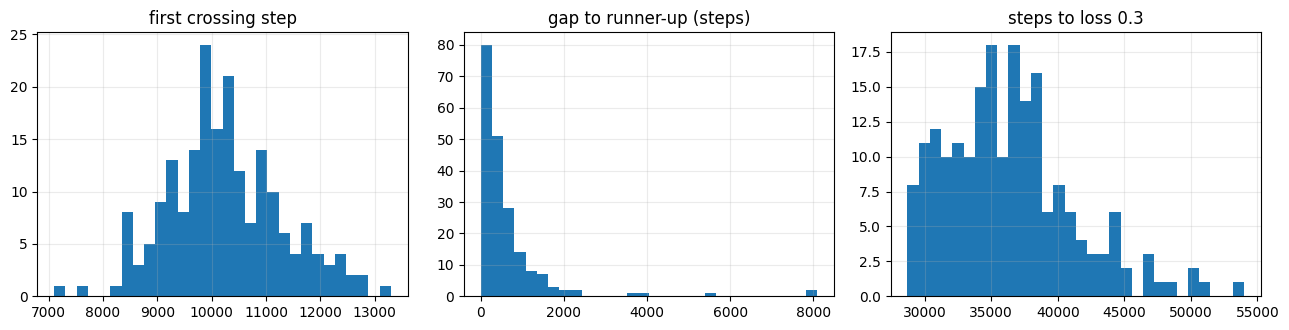

,init_seed,final_step,final_loss,winner,winner_step,winner_cos_end,runner_up,gap_steps,leading_set,n_on_direction_end
0,6178,35200,0.299708,30,9800,-0.997553,37,200,"30,37",4
1,6201,38600,0.298594,20,10100,-0.998337,23,300,"20,23",3
2,6202,32900,0.297509,12,10100,0.963843,25,700,12,3
3,6203,30400,0.297559,38,11000,-0.999227,18,5500,38,3
4,6204,35000,0.299579,5,10400,-0.998220,9,1900,5,3
5,6205,32200,0.297579,26,12100,0.991039,11,600,26,4
6,7000,30200,0.299532,22,9900,0.987772,24,1700,22,4
7,7001,35500,0.296960,37,10500,-0.996010,30,1200,37,3
8,7002,28700,0.299663,19,12400,-0.997126,29,1300,19,4
9,7003,34200,0.299268,2,9900,0.998700,7,700,2,3


In [5]:
table_b = sweep_capture_table(PART_B_DIR, threshold=THRESHOLD, tie_window_steps=TIE_WINDOW_STEPS)
tree_b = load_tree(PART_B_DIR / "tree.npz")
print(f"{len(table_b)} runs; stopped by loss: {(table_b.stopped_by == 'stop_loss').sum()}, by max_steps: {(table_b.stopped_by == 'max_steps').sum()}")
print(f"runs with a u_0 capture: {(table_b.winner >= 0).sum()} / {len(table_b)}")
print("leading-set size distribution:", table_b.n_leading.value_counts().sort_index().to_dict())
print("neurons on u_0 at loss 0.3, distribution:", table_b.n_on_direction_end.value_counts().sort_index().to_dict())
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].hist(table_b.winner_step[table_b.winner >= 0], bins=30); axes[0].set_title("first crossing step")
axes[1].hist(table_b.gap_steps[table_b.runner_up >= 0], bins=30); axes[1].set_title("gap to runner-up (steps)")
axes[2].hist(table_b.final_step, bins=30); axes[2].set_title("steps to loss 0.3")
for ax in axes: ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()
display(table_b[["init_seed", "final_step", "final_loss", "winner", "winner_step", "winner_cos_end",
                 "runner_up", "gap_steps", "leading_set", "n_on_direction_end"]].head(12))

### Per-neuron init features and where the winner ranks

For every init, 40 rows of features at initialization and at the end of the plateau (first
snapshot with trailing loss <= 0.69), plus the outcome. The population gradient and lens at
init are computed on a fresh 100k-point sample from the same ODT, independent of the training
data. This cell is the expensive one (a few seconds per init).

In [6]:
FEATURE_N = 100_000
FEATURE_DATA_SEED = 999_001
_spec0 = load_run(table_b.path.iloc[0])["spec"]
x_feat, y_feat = build_data(SweepRunSpec(**{**_spec0.__dict__, "n_train": FEATURE_N, "data_seed": FEATURE_DATA_SEED}), tree_b)

frames = []
for i, r in enumerate(table_b.itertuples()):
    run = load_run(r.path)
    frames.append(init_neuron_features(run, tree_b, x_feat, y_feat, device=DEVICE,
                                       threshold=THRESHOLD, tie_window_steps=TIE_WINDOW_STEPS))
    if (i + 1) % 25 == 0:
        print(f"  features for {i + 1}/{len(table_b)} inits")
features = pd.concat(frames, ignore_index=True)
features.to_csv(PART_B_DIR / "init_neuron_features.csv", index=False)
print(features.shape)

  features for 25/200 inits


  features for 50/200 inits


  features for 75/200 inits


  features for 100/200 inits


  features for 125/200 inits


  features for 150/200 inits


  features for 175/200 inits


  features for 200/200 inits
(8000, 24)


In [7]:
# Where does the first crosser rank among its 39 siblings, feature by feature?
rank_first = winner_rank_table(features, outcome_col="is_winner")
display(rank_first)

,feature,n_inits,mean_percentile,median_percentile,frac_top_decile,frac_bottom_decile,frac_above_median,p_sign_test
0,disp_norm_plateau,200,0.839359,0.897436,0.455,0.000,0.945,5.121218e-43
1,norm_ratio_plateau,200,0.824359,0.897436,0.430,0.000,0.930,1.586418e-39
2,abs_cos_u0_plateau,200,0.767051,0.846154,0.370,0.015,0.845,3.413491e-24
3,abs_cos_u0_init,200,0.726667,0.820513,0.330,0.015,0.800,3.384016e-18
4,fanout_norm_plateau,200,0.684231,0.769231,0.275,0.040,0.760,8.738435e-14
5,lens_std_init,200,0.665128,0.743590,0.265,0.055,0.740,7.261224e-12
6,lens_abs_mean_init,200,0.669487,0.769231,0.230,0.040,0.730,5.674278e-11
7,grad_norm_init,200,0.660256,0.717949,0.205,0.020,0.725,1.528055e-10
8,grad_abs_cos_common_init,200,0.624103,0.692308,0.175,0.055,0.705,6.307982e-09
9,grad_level4_fraction_init,200,0.621667,0.666667,0.185,0.060,0.690,8.026906e-08


In [8]:
# Same question for membership in the leading set (near-ties count as winners): compare the
# leading-set members' feature distribution against everyone else, pooled over inits.
lead = features[features.in_leading_set == 1]
rest = features[features.in_leading_set == 0]
feat_cols = [c for c in rank_first.feature]
rows = []
for c in feat_cols:
    a, b = lead[c].to_numpy(float), rest[c].to_numpy(float)
    # rank-biserial: P(lead > rest) - P(lead < rest), from the pooled ranks
    pooled = pd.Series(np.concatenate([a, b])).rank().to_numpy()
    ra = pooled[: len(a)]
    auc = (ra.sum() - len(a) * (len(a) + 1) / 2) / (len(a) * len(b))
    rows.append({"feature": c, "n_lead": len(a), "n_rest": len(b), "P(lead > rest)": auc,
                 "lead_median": np.median(a), "rest_median": np.median(b)})
lead_vs_rest = pd.DataFrame(rows).sort_values("P(lead > rest)", key=lambda s: (s - 0.5).abs(), ascending=False)
display(lead_vs_rest)

,feature,n_lead,n_rest,P(lead > rest),lead_median,rest_median
0,disp_norm_plateau,332,7668,0.835734,0.183301,0.076674
1,norm_ratio_plateau,332,7668,0.819565,1.072045,1.015633
2,abs_cos_u0_plateau,332,7668,0.773732,0.141339,0.066200
3,abs_cos_u0_init,332,7668,0.718146,0.129148,0.066546
4,fanout_norm_plateau,332,7668,0.686565,0.637477,0.586599
6,lens_abs_mean_init,332,7668,0.654944,0.006502,0.005331
7,grad_norm_init,332,7668,0.653966,0.000057,0.000036
5,lens_std_init,332,7668,0.640934,0.009977,0.008752
9,grad_level4_fraction_init,332,7668,0.620021,0.880822,0.826111
8,grad_abs_cos_common_init,332,7668,0.619703,0.935096,0.892975


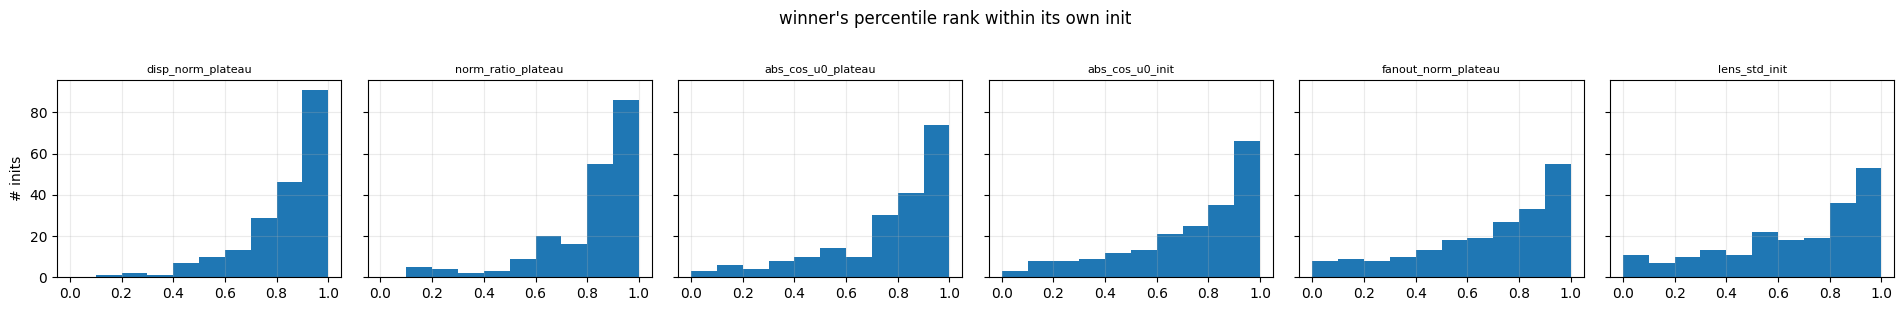

In [9]:
# Winner percentile histograms for the strongest features
top = rank_first.head(6).feature.tolist()
fig, axes = plt.subplots(1, len(top), figsize=(3.2 * len(top), 3.0), sharey=True)
for ax, c in zip(np.atleast_1d(axes), top):
    pct = []
    for _, g in features.groupby("init_seed"):
        if g.is_winner.sum() != 1:
            continue
        v = g[c].to_numpy(float); w = v[g.is_winner.to_numpy() == 1][0]
        pct.append(((v < w).sum() + 0.5 * ((v == w).sum() - 1)) / (len(v) - 1))
    ax.hist(pct, bins=10, range=(0, 1)); ax.set_title(c, fontsize=8); ax.grid(alpha=0.25)
axes[0].set_ylabel("# inits")
fig.suptitle("winner's percentile rank within its own init", y=1.02)
fig.tight_layout(); plt.show()

### Can the winner be predicted from the init?

Leave-one-init-out conditional logit: a linear score over per-neuron features, softmax over
the 40 neurons of an init, trained on the other inits. Reported: how often the top-scored neuron
is the first crosser (chance 1/40), how often it is in the leading set, and the median rank of
the true winner. Signed features enter as absolute values. Three feature sets: static features
at initialization only; features at the end of the plateau, which are a deterministic function
of the init under the flow; and both.

In [10]:
features["abs_neg_grad_cos_u0_init"] = features["neg_grad_cos_u0_init"].abs()
INIT_COLS = ["abs_cos_u0_init", "norm_init", "fanout_norm_init", "grad_norm_init", "grad_abs_cos_common_init",
             "grad_level4_fraction_init", "abs_neg_grad_cos_u0_init", "lens_abs_mean_init", "lens_std_init"]
PLATEAU_COLS = ["abs_cos_u0_plateau", "norm_ratio_plateau", "disp_norm_plateau", "abs_disp_cos_u0_plateau", "fanout_norm_plateau"]
pred_table, pred_weights = winner_prediction_cv(features, {
    "abs_cos_u0_init only": ["abs_cos_u0_init"],
    "init features": INIT_COLS,
    "plateau features": PLATEAU_COLS,
    "init + plateau": INIT_COLS + PLATEAU_COLS,
})
display(pred_table)
print("weights, init-only model (features z-scored within init):")
for k, v in sorted(pred_weights["init features"].items(), key=lambda kv: -abs(kv[1])):
    print(f"  {k:28s} {v:+.3f}")

,feature_set,n_inits,n_features,top1,top1_in_leading_set,median_winner_rank,top3,chance_top1
0,abs_cos_u0_init only,200,1,0.115,0.160,8.0,0.255,0.025
1,init features,200,9,0.150,0.235,7.0,0.295,0.025
2,plateau features,200,5,0.365,0.580,3.0,0.570,0.025
3,init + plateau,200,14,0.385,0.595,2.0,0.605,0.025


weights, init-only model (features z-scored within init):
  abs_cos_u0_init              +0.711
  grad_norm_init               +0.434
  lens_std_init                +0.373
  grad_abs_cos_common_init     +0.358
  abs_neg_grad_cos_u0_init     +0.339
  lens_abs_mean_init           -0.287
  norm_init                    -0.199
  grad_level4_fraction_init    -0.145
  fanout_norm_init             +0.021


### Trajectories for a few inits

Signed cosine with u_0 of every first-layer neuron over steps, winner highlighted.

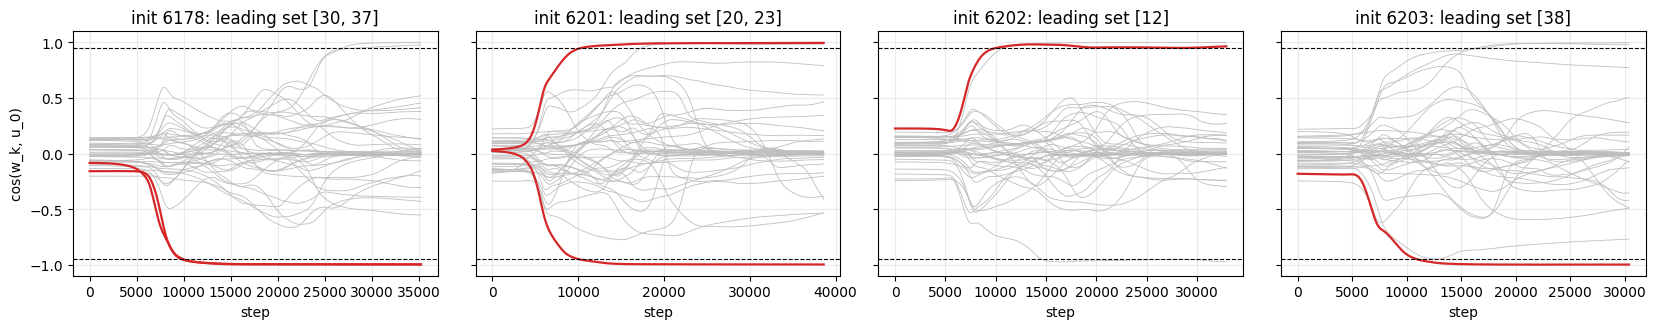

In [11]:
show = table_b[table_b.winner >= 0].head(4)
fig, axes = plt.subplots(1, len(show), figsize=(4.2 * len(show), 3.4), sharey=True, squeeze=False)
for ax, r in zip(axes[0], show.itertuples()):
    run = load_run(r.path)
    cos = signed_cosines_with_direction(run["weights"][FIRST_LAYER_KEY], tree_b.w_list[0])
    lead = [int(k) for k in r.leading_set.split(",") if r.leading_set]
    for k in range(cos.shape[1]):
        ax.plot(run["snapshot_steps"], cos[:, k], color="tab:red" if k in lead else "0.75",
                lw=1.6 if k in lead else 0.6, zorder=2 if k in lead else 1)
    ax.axhline(THRESHOLD, color="k", ls="--", lw=0.8); ax.axhline(-THRESHOLD, color="k", ls="--", lw=0.8)
    ax.set_title(f"init {r.init_seed}: leading set {lead}"); ax.set_xlabel("step"); ax.grid(alpha=0.25)
axes[0, 0].set_ylabel("cos(w_k, u_0)")
fig.tight_layout(); plt.show()